# SGD and Backpropagation - Exercises

**NOTICE:**
1. You are allowed to work in groups of up to three people but **have to document** your group's\
 members in the top cell of your notebook.
2. **Comment your code**, explain what you do (refer to the slides). It will help you understand the topics\
 and help me understand your thinking progress. Quality of comments will be graded.
3. **Discuss** and analyze your results, **write-down your learnings**. These exercises are no programming\
 exercises it is about learning and getting a touch for these methods. Such questions might be asked in the\
 final exams.
 4. Feel free to **experiment** with these methods. Change parameters think about improvements, write down\
 what you learned. This is not only about collecting points for the final grade, it is about understanding\
  the methods.

### Exercise 1 - Gradient Descent


**Summary:** In this exercise you will implement the gradient descent algorithm. It will\
help you to gain a better understanding on how neural networks are trained.


**Provided Code:** In the cell below I have provided you with a function ``f()`` and the first\
derivative of ``f()`` denoted ``dfdx()``.


**Your Tasks in this exercise:**
1. Implement the gradient descent algorithm.
2. Plot and analyze your results.





In [1]:
#@title **Provided Code:** ``f()`` and ``dfdx()`` function.

import matplotlib.pyplot as plt
import numpy as np


def f(x):
    return x**2

def dfdx(x):
    return 2*x

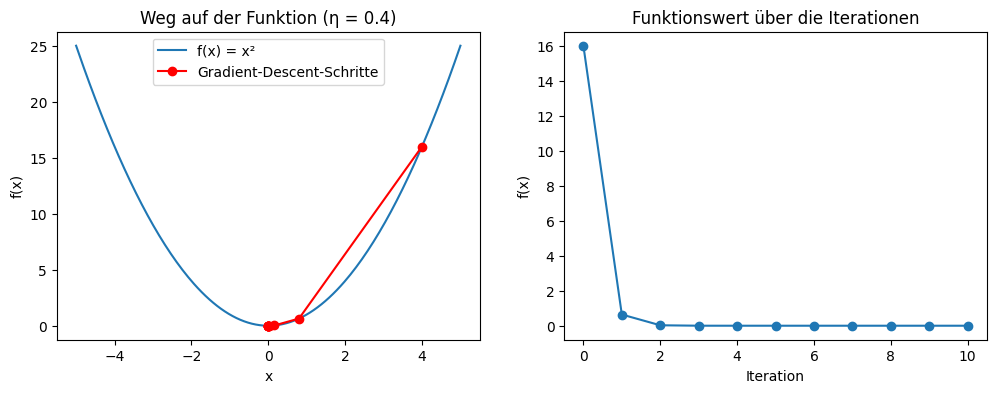

In [8]:
x = 4.0
learning_rate = 0.4
n_steps = 10

history = [x]
for _ in range(n_steps):
    x = x - learning_rate * dfdx(x)
    history.append(x)

xs = np.array(history)


x_plot = np.linspace(-5, 5, 200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(x_plot, f(x_plot), label="f(x) = x²")
ax1.plot(xs, f(xs), "o-", color="red", label="Gradient-Descent-Schritte")
ax1.set_xlabel("x")
ax1.set_ylabel("f(x)")
ax1.set_title(f"Weg auf der Funktion (η = {learning_rate})")
ax1.legend()

ax2.plot(f(xs), "o-")
ax2.set_xlabel("Iteration")
ax2.set_ylabel("f(x)")
ax2.set_title("Funktionswert über die Iterationen")

plt.show()

### Exercise 2 - Gradient Descent with Momentum


**Summary:** In this exercise you will improve the gradient descent algorithm from the\
previous exercise to act using the momentum idea.


**Provided Code:** In the cell below I have provided you with a function ``g()``.


**Your Tasks in this exercise:**
1. Calculate the gradient of ``g()`` with respect to x.
2. Extend your implementation of gradient descent with momentum.
3. Try to find a minimum of ``g()``.
4. Answer the following questions:
    * What is a good value fo $\alpha$?
    * What is the impact of the initialization of your optimization (the starting point)?
    * Why do neural networks produce different results if trained multiple times?




In [14]:
# A non-convex function.
#
def g(x):
    return np.exp(-(x**2)) * np.sin(x**3)

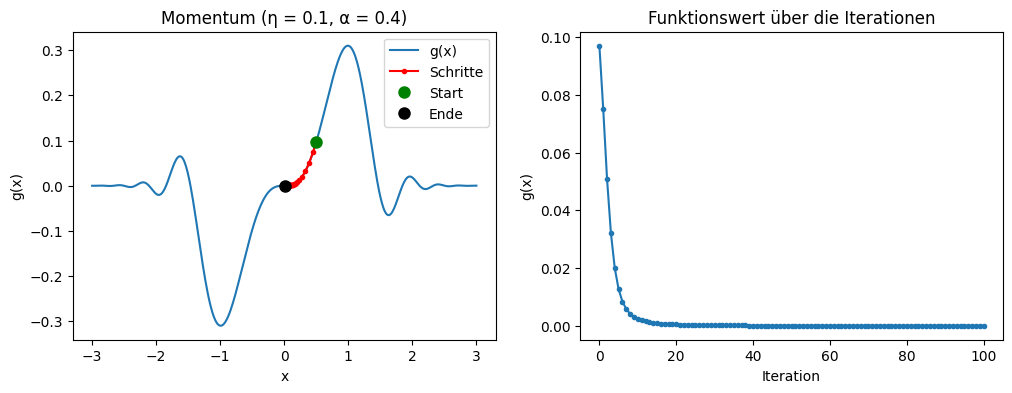

In [20]:
#1.
def dgdx(x):
    return np.exp(-x**2) * (3*x**2 * np.cos(x**3) - 2*x * np.sin(x**3))

#2.
x = 0.5
learning_rate = 0.1
alpha = 0.4
n_steps = 100

v = 0.0
history = [x]
for _ in range(n_steps):
  v = alpha * v - learning_rate * dgdx(x)
  x = x + v
  history.append(x)

xs = np.array(history)


x_plot = np.linspace(-3, 3, 500)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(x_plot, g(x_plot), label="g(x)")
ax1.plot(xs, g(xs), "o-", color="red", markersize=3, label="Schritte")
ax1.plot(xs[0], g(xs[0]), "go", markersize=8, label="Start")
ax1.plot(xs[-1], g(xs[-1]), "ko", markersize=8, label="Ende")
ax1.set_xlabel("x")
ax1.set_ylabel("g(x)")
ax1.set_title(f"Momentum (η = {learning_rate}, α = {alpha})")
ax1.legend()

ax2.plot(g(xs), "o-", markersize=3)
ax2.set_xlabel("Iteration")
ax2.set_ylabel("g(x)")
ax2.set_title("Funktionswert über die Iterationen")

plt.show()

1. Guter Wert für α: Etwa 0.9. Ist α zu klein (z. B. 0.4), reicht der Schwung nicht, um die flache Stelle bei x = 0 zu überwinden. Ist α zu groß (z. B. 0.99), pendelt die Kugel zu lange um das Minimum und kommt nicht zur Ruhe.

2. Einfluss des Startpunkts: Sehr groß. Gradient Descent landet in dem Tal, das vom Startpunkt aus erreichbar ist, oft also nur in einem lokalen Minimum. Bei x = 0 oder weit außen ist die Steigung fast 0, dann bewegt sich kaum etwas. Startet man bei 0.5, findet man mit Momentum das globale Minimum bei x ≈ −1, startet man bei 1.5, bleibt man im lokalen Minimum bei x ≈ 1.6 hängen.

3. Unterschiedliche Ergebnisse bei neuronalen Netzen: Ihre Fehlerfunktion ist ebenfalls nicht-konvex und hat viele lokale Minima. Da die Gewichte zufällig initialisiert und die Trainingsdaten zufällig gemischt werden, startet jedes Training an einem anderen Punkt, nimmt einen anderen Weg und landet in einem anderen Minimum.